## 다음 영화 리뷰 데이터 분석
1. 데이터 로딩
2. 텍스트 전처리
3. 빈도수 계산
4. 시각화

In [1]:
# 데이터 로딩
datafile = "../data/daum_movie_review.csv"

import pandas as pd
df = pd.read_csv(datafile)

In [2]:
df.head()

,review,rating,date,title
0,돈 들인건 티가 나지만 보는 내내 하품만,1,2018.10.29,인피니티 워
1,몰입할수밖에 없다. 어렵게 생각할 필요없다. 내가 전투에 참여한듯 손에 땀이남.,10,2018.10.26,인피니티 워
2,이전 작품에 비해 더 화려하고 스케일도 커졌지만.... 전국 맛집의 음식들을 한데 ...,8,2018.10.24,인피니티 워
3,이 정도면 볼만하다고 할 수 있음!,8,2018.10.22,인피니티 워
4,재미있다,10,2018.10.20,인피니티 워


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14725 entries, 0 to 14724
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   review  14725 non-null  str  
 1   rating  14725 non-null  int64
 2   date    14725 non-null  str  
 3   title   14725 non-null  str  
dtypes: int64(1), str(3)
memory usage: 460.3 KB


In [4]:
# 품사 태깅 -> 토큰화, 불용어제거
from konlpy.tag import Okt

tagger = Okt()
reviews = list(df.review)

# pos_list = []
# for review in reviews:
#     tokens = tagger.pos(review)
#     pos_list.append(tokens)
pos_list = [tagger.pos(review) for review in reviews]
len(pos_list)

14725

In [5]:
pos_list[:1]

[[('돈', 'Noun'),
  ('들인건', 'Verb'),
  ('티', 'Noun'),
  ('가', 'Josa'),
  ('나', 'Noun'),
  ('지만', 'Josa'),
  ('보는', 'Verb'),
  ('내내', 'Noun'),
  ('하품', 'Noun'),
  ('만', 'Josa')]]

In [6]:
# 불용어 제거 -> 필요한 품사의 단어만 추출
my_tags = ['Noun', 'Verb', 'Adjective']
my_stopwords = ['영화', '것', '이', '잘', '더', '점', '좀', '입니다', '하는', '그']

# result_list = []
# for review in pos_list:
#     for word, tag in review:
#         if tag in my_tags and word not in my_stopwords:
#             result_list.append(word)
# result_list[:10]

# result_list = [word for review in pos_list for word, tag in review 
#                if tag in my_tags and word not in my_stopwords]

result_list = []
for review in reviews:
    result_list += [word for word, tag in tagger.pos(review)
                    if tag in my_tags and word not in my_stopwords]
result_list[:10]


['돈', '들인건', '티', '나', '보는', '내내', '하품', '몰입', '할수밖에', '없다']

In [7]:
# 빈도수 계산 -> Counter 객체를 생성하여 사용
from collections import Counter

counter = Counter(result_list)
count_list = counter.most_common(20)
print(count_list)

[('연기', 1293), ('감동', 1223), ('생각', 1027), ('정말', 948), ('배우', 847), ('사람', 819), ('스토리', 815), ('진짜', 781), ('눈물', 737), ('보고', 709), ('최고', 682), ('재미', 641), ('마지막', 612), ('시간', 596), ('마동석', 556), ('수', 536), ('그냥', 533), ('정도', 531), ('광주', 530), ('윤계상', 517)]


In [18]:
# matplotlib 한글폰트 설정
import matplotlib.pyplot as plt
font_path = 'C:/Windows/Fonts/malgun.ttf'
from matplotlib import font_manager, rc
font_name = font_manager.FontProperties(fname=font_path).get_name()
rc('font', family=font_name)

In [9]:
count = {}
for word in result_list:
    # count[word] = count.get(word, 0) + 1:
    if word not in count.keys():
        count[word] = 0
    count[word] += 1
print(count)

{'돈': 489, '들인건': 1, '티': 49, '나': 353, '보는': 401, '내내': 170, '하품': 33, '몰입': 210, '할수밖에': 2, '없다': 195, '어렵게': 5, '생각': 1027, '할': 480, '필요없다': 15, '내': 421, '전투': 11, '참여': 8, '듯': 366, '손': 50, '땀': 7, '이남': 3, '이전': 16, '작품': 241, '비해': 36, '화려하고': 14, '스케일': 60, '커졌지만': 1, '전국': 6, '맛집': 1, '음식': 10, '모은': 2, '좋았으나': 22, '걸': 224, '모두': 245, '한': 268, '그릇': 2, '섞어': 5, '버린': 28, '느낌': 400, '다음': 207, '기대하게': 11, '만든다': 14, '정도': 531, '볼': 476, '하다고': 6, '수': 536, '있음': 58, '재미있다': 44, '재밌게': 335, '봄': 148, '줄': 197, '없냐': 4, '헐': 24, '죽었어': 1, '나중': 56, '앤트맨': 13, '보다가도': 1, '깜놀': 16, '충격': 59, '결말': 183, '응집': 1, '개연': 83, '성은': 16, '무시': 19, '해라': 28, '액션': 268, '즐겨라': 5, '스타로드': 14, '이끌어': 11, '준다': 50, '각각': 10, '영웅': 67, '적': 40, '신념': 3, '얼마나': 95, '부질없는지': 1, '보셔라': 2, '졸라': 16, '이상하네': 2, '대박': 184, '정말': 948, '지루할': 49, '틈': 55, '넘잘': 1, '만들었다': 47, '역시': 256, '대단하다': 26, '어벤져스': 145, '마지막': 612, '누구': 69, '연락': 3, '거지': 27, '궁금': 5, '편이': 112, '궁굼': 2, '해지네요': 1, '잼있는': 

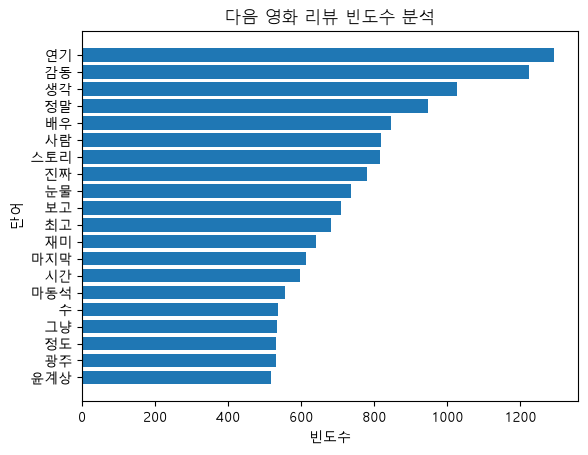

In [10]:
# 시각화 - 수평 막대 그래프


# (1) 데이터 준비
x = [word for word, count in count_list]
y = [count for word, count in count_list]

# x = [], y = []
# for word, count in count_list:
#     x.append(word)
#     y.append(count)

# (2) 그래프 생성
plt.barh(x[::-1], y[::-1])

# (3) 필요한 정보 추가
plt.title("다음 영화 리뷰 빈도수 분석")
plt.xlabel("빈도수")
plt.ylabel("단어")

# (4) 출력
plt.show()
# plt.savefig("D:/Lecture/Pydata26/result/daum_movie_review_graph.png")

In [11]:
# 대한민국 헌법 wordcloud 생성하기
from konlpy.corpus import kolaw
input_filename = 'constitution.txt'
const_doc = kolaw.open(input_filename).read()
type(const_doc), len(const_doc)

(str, 18884)

In [12]:
const_doc[:100]

'대한민국헌법\n\n유구한 역사와 전통에 빛나는 우리 대한국민은 3·1운동으로 건립된 대한민국임시정부의 법통과 불의에 항거한 4·19민주이념을 계승하고, 조국의 민주개혁과 평화적 통일의'

In [13]:
# wordcloud 설치
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


In [24]:
from wordcloud import WordCloud

font_path = 'C:/Windows/Fonts/malgun.ttf'

# WordCloud 클래스의 객체 생성
wc = WordCloud(
    font_path = font_path
)

In [25]:

# 워드클라우드 생성 from 텍스트
wc = wc.generate(const_doc)

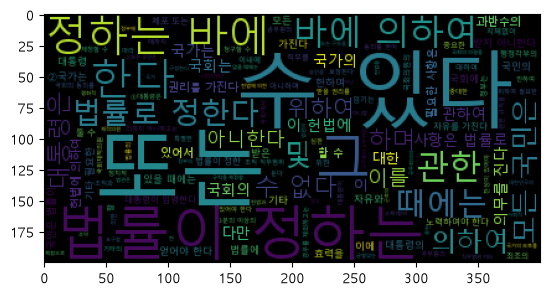

In [26]:
# matplotlib의 pyplot과 연동
import matplotlib.pyplot as plt
plt.imshow(wc)

# pyplot의 객체를 화면으로 출력
plt.show()

In [ ]:
# 헌법 -> 전처리 -> 빈도수 객체 (Counter)

# 전처리 : 도큰화, 정제, 정규화 -> 품사태깅, 불용어제거
# 품사태깅
from konlpy.tag import Okt
tagger = Okt().pos

tokens = tagger(const_doc)
tokens[:10]

[('대한민국', 'Noun'),
 ('헌법', 'Noun'),
 ('\n\n', 'Foreign'),
 ('유구', 'Noun'),
 ('한', 'Josa'),
 ('역사', 'Noun'),
 ('와', 'Josa'),
 ('전통', 'Noun'),
 ('에', 'Josa'),
 ('빛나는', 'Verb')]

In [48]:
# 불용어 제거 : 원하는 품사 정의, 삭제할 단어 사전 정의
my_tags = ['Noun']
my_stopwords = ['법률', '제', '정', '수', '때']

result_list = [word for word, tag in tokens if tag in my_tags and word not in my_stopwords]
result_list[:10]

['대한민국', '헌법', '유구', '역사', '전통', '우리', '국민', '운동', '건립', '대한민국']

In [49]:
# 빈도수 계산 : Counter 클래스
from collections import Counter
counter = Counter(result_list)

In [55]:
from wordcloud import WordCloud

font_path = 'C:/Windows/Fonts/malgun.ttf'

# WordCloud 클래스의 객체 생성
wc = WordCloud(
    font_path = font_path,
    background_color = 'ivory',
    width = 800,
    height = 600,
    max_words = 100
)

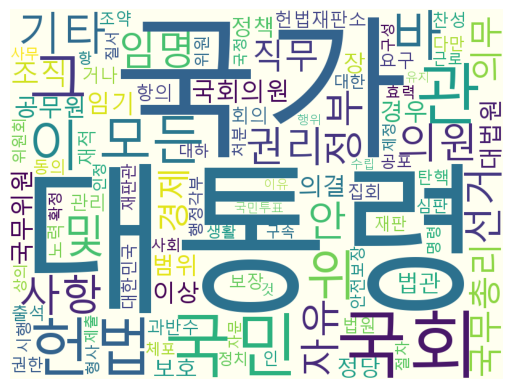

In [56]:
# 워드클라우드 적용
wc = wc.generate_from_frequencies(counter)
plt.imshow(wc)
plt.axis('off')
plt.show()

In [59]:
# wordcloud 이미지를 파일로 저장
wc.to_file("../result/const_doc_wordcloud.jpg")